# Smoking Detection — (YOLO26s)

**Before running:**
1. Attach dataset `cigarette-detection` (right sidebar → Add Data)
2. **Settings → Accelerator → GPU P100** (or T4 x2)
3. **Settings → Internet → On**

**Pipeline:** Verify env → Install → Copy to local SSD → Write data.yaml → Train → Validate → Inference → Save weights

## 1. Verify environment

In [1]:
!nvidia-smi
!free -h
!nproc
!ls /kaggle/input/datasets/omarmdiab/cigarette-detection

Tue Oct 13 16:41:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Install Ultralytics

In [2]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.6 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 5.2 MB/s eta 0:00:00


## 3. Copy dataset to fast local SSD
`/kaggle/input/` is read-only and slow. `/kaggle/temp/` is local SSD. We only care about **train** and **val** — test is ignored.

In [3]:
import shutil, os, time, glob

CANDS = [
    '/kaggle/input/datasets/omarmdiab/cigarette-detection',
]

SRC = None
for c in CANDS:
    if os.path.isdir(c) and os.path.isdir(f'{c}/images'):
        SRC = c
        break

if SRC is None:
    # Fallback: search anywhere under /kaggle/input for a folder containing images/
    for root, dirs, _ in os.walk('/kaggle/input'):
        if 'images' in dirs and 'labels' in dirs:
            SRC = root
            break

assert SRC, "❌ Could not find dataset with images/ and labels/ under /kaggle/input"
print(f'✅ Dataset root: {SRC}')

DST = '/kaggle/temp/local_dataset'

# ── Copy to fast local SSD ──
if not os.path.exists(DST):
    print('📥 Copying to local SSD...')
    t0 = time.time()
    shutil.copytree(SRC, DST)
    print(f'✅ Done in {time.time()-t0:.1f}s')
else:
    print(f'✅ Already present: {DST}')

# ── Nuke stray locks / caches ──
for pat in ['**/*.lock', '**/.*.lock', '**/*.cache']:
    for f in glob.glob(os.path.join(DST, pat), recursive=True):
        os.remove(f); print('🗑️ ', f)

# ── Verify train/val ──
for split in ['train', 'val']:
    imgs = len(os.listdir(f'{DST}/images/{split}'))
    lbls = len(os.listdir(f'{DST}/labels/{split}'))
    flag = '✅' if imgs == lbls else '❌ MISMATCH'
    print(f'{split:5s}  images={imgs:6d}  labels={lbls:6d}  {flag}')

✅ Dataset root: /kaggle/input/datasets/omarmdiab/cigarette-detection
📥 Copying to local SSD...
✅ Done in 210.2s
train  images= 12259  labels= 12259  ✅
val    images=  1152  labels=  1152  ✅


In [8]:
import os, glob
from collections import Counter

LOCAL = '/kaggle/temp/local_dataset'

print('=' * 60)
print('FOLDER ANALYSIS —', LOCAL)
print('=' * 60)

# ── 1. Top-level structure ──
print('\n📁 Top-level contents:')
for entry in sorted(os.listdir(LOCAL)):
    p = os.path.join(LOCAL, entry)
    tag = '📁' if os.path.isdir(p) else '📄'
    print(f'   {tag} {entry}')

# ── 2. Per-split counts: images vs labels ──
print('\n📊 Per-split counts:')
print(f'   {"split":<8} {"images":>8} {"labels":>8}  {"status"}')
print('   ' + '-' * 44)

expected = {'train': 12259, 'val': 1152, 'test': 898}

for split in ['train', 'val', 'test']:
    img_dir = f'{LOCAL}/images/{split}'
    lbl_dir = f'{LOCAL}/labels/{split}'
    if not os.path.isdir(img_dir):
        print(f'   {split:<8} {"—":>8} {"—":>8}  ❌ missing')
        continue
    imgs = os.listdir(img_dir)
    lbls = os.listdir(lbl_dir) if os.path.isdir(lbl_dir) else []
    n_img, n_lbl = len(imgs), len(lbls)
    ok = '✅' if n_img == n_lbl else '❌ mismatch'
    exp = expected.get(split, '?')
    print(f'   {split:<8} {n_img:>8} {n_lbl:>8}  {ok}   (expected ~{exp})')

# ── 3. Filename pairing check (images vs labels stems) ──
print('\n🔗 Filename pairing check:')
for split in ['train', 'val', 'test']:
    img_dir = f'{LOCAL}/images/{split}'
    lbl_dir = f'{LOCAL}/labels/{split}'
    if not (os.path.isdir(img_dir) and os.path.isdir(lbl_dir)):
        continue
    img_stems = {os.path.splitext(f)[0] for f in os.listdir(img_dir)}
    lbl_stems = {os.path.splitext(f)[0] for f in os.listdir(lbl_dir)}
    missing_lbl = img_stems - lbl_stems
    orphan_lbl  = lbl_stems - img_stems
    print(f'   {split:<8} images_without_label={len(missing_lbl):>5}   '
          f'labels_without_image={len(orphan_lbl):>5}')

# ── 4. Image extensions seen ──
print('\n🖼️  Image extensions:')
for split in ['train', 'val', 'test']:
    img_dir = f'{LOCAL}/images/{split}'
    if not os.path.isdir(img_dir):
        continue
    exts = Counter(os.path.splitext(f)[1].lower() for f in os.listdir(img_dir))
    print(f'   {split:<8} {dict(exts)}')

# ── 5. Sample some label files (line counts, class ids) ──
print('\n📝 Label file sanity (sampling up to 200 per split):')
for split in ['train', 'val', 'test']:
    lbl_dir = f'{LOCAL}/labels/{split}'
    if not os.path.isdir(lbl_dir):
        continue
    files = os.listdir(lbl_dir)[:200]
    empty, malformed, class_ids = 0, 0, Counter()
    for f in files:
        try:
            with open(os.path.join(lbl_dir, f)) as fh:
                lines = [l.strip() for l in fh if l.strip()]
            if not lines:
                empty += 1
                continue
            for line in lines:
                parts = line.split()
                if len(parts) != 5:
                    malformed += 1
                else:
                    class_ids[int(float(parts[0]))] += 1
        except Exception:
            malformed += 1
    print(f'   {split:<8} empty={empty:<4} malformed={malformed:<4} '
          f'class_ids={dict(class_ids)}')

print('\n' + '=' * 60)
print('Done. Nothing was modified — read-only analysis.')
print('=' * 60)

FOLDER ANALYSIS — /kaggle/temp/local_dataset

📁 Top-level contents:
   📁 images
   📁 labels

📊 Per-split counts:
   split      images   labels  status
   --------------------------------------------
   train       12259    12259  ✅   (expected ~12259)
   val          1152     1152  ✅   (expected ~1152)
   test          558      558  ✅   (expected ~898)

🔗 Filename pairing check:
   train    images_without_label=    0   labels_without_image=    0
   val      images_without_label=    0   labels_without_image=    0
   test     images_without_label=    0   labels_without_image=    0

🖼️  Image extensions:
   train    {'.jpg': 12239, '.webp': 20}
   val      {'.jpg': 1149, '.webp': 3}
   test     {'.jpg': 556, '.webp': 2}

📝 Label file sanity (sampling up to 200 per split):
   train    empty=1    malformed=0    class_ids={0: 263}
   val      empty=15   malformed=0    class_ids={0: 227}
   test     empty=0    malformed=0    class_ids={0: 238}

Done. Nothing was modified — read-only analysis.

In [9]:
import os

LOCAL = '/kaggle/temp/local_dataset'

# Delete labels that have no matching image
for split in ['train', 'val', 'test']:
    img_dir = f'{LOCAL}/images/{split}'
    lbl_dir = f'{LOCAL}/labels/{split}'

    img_stems = {os.path.splitext(f)[0] for f in os.listdir(img_dir)}
    lbl_files = os.listdir(lbl_dir)

    removed = 0
    for lbl in lbl_files:
        if os.path.splitext(lbl)[0] not in img_stems:
            os.remove(os.path.join(lbl_dir, lbl))
            removed += 1

    print(f'{split:<6}  removed {removed} orphan label(s)')

# Re-verify
print('\n✅ Post-cleanup verification:')
for split in ['train', 'val', 'test']:
    imgs = len(os.listdir(f'{LOCAL}/images/{split}'))
    lbls = len(os.listdir(f'{LOCAL}/labels/{split}'))
    flag = '✅' if imgs == lbls else '❌'
    print(f'   {split:<6}  images={imgs:>6}  labels={lbls:>6}  {flag}')

train   removed 0 orphan label(s)
val     removed 0 orphan label(s)
test    removed 0 orphan label(s)

✅ Post-cleanup verification:
   train   images= 12259  labels= 12259  ✅
   val     images=  1152  labels=  1152  ✅
   test    images=   558  labels=   558  ✅


## 4. Write `data.yaml`
`test: images/val` intentionally — the test folder is corrupted, and this makes any accidental test access fall back to val instead of crashing.

In [10]:
import os, yaml

LOCAL = '/kaggle/temp/local_dataset'
yaml_path = os.path.join(LOCAL, 'data.yaml')

cfg = {
    'path' : LOCAL,
    'train': 'images/train',
    'val'  : 'images/val',
    'test' : 'images/test',     
    'nc'   : 1,
    'names': ['cigarette'],
}
yaml.safe_dump(cfg, open(yaml_path, 'w'), sort_keys=False)
print(open(yaml_path).read())

path: /kaggle/temp/local_dataset
train: images/train
val: images/val
test: images/test
nc: 1
names:
- cigarette



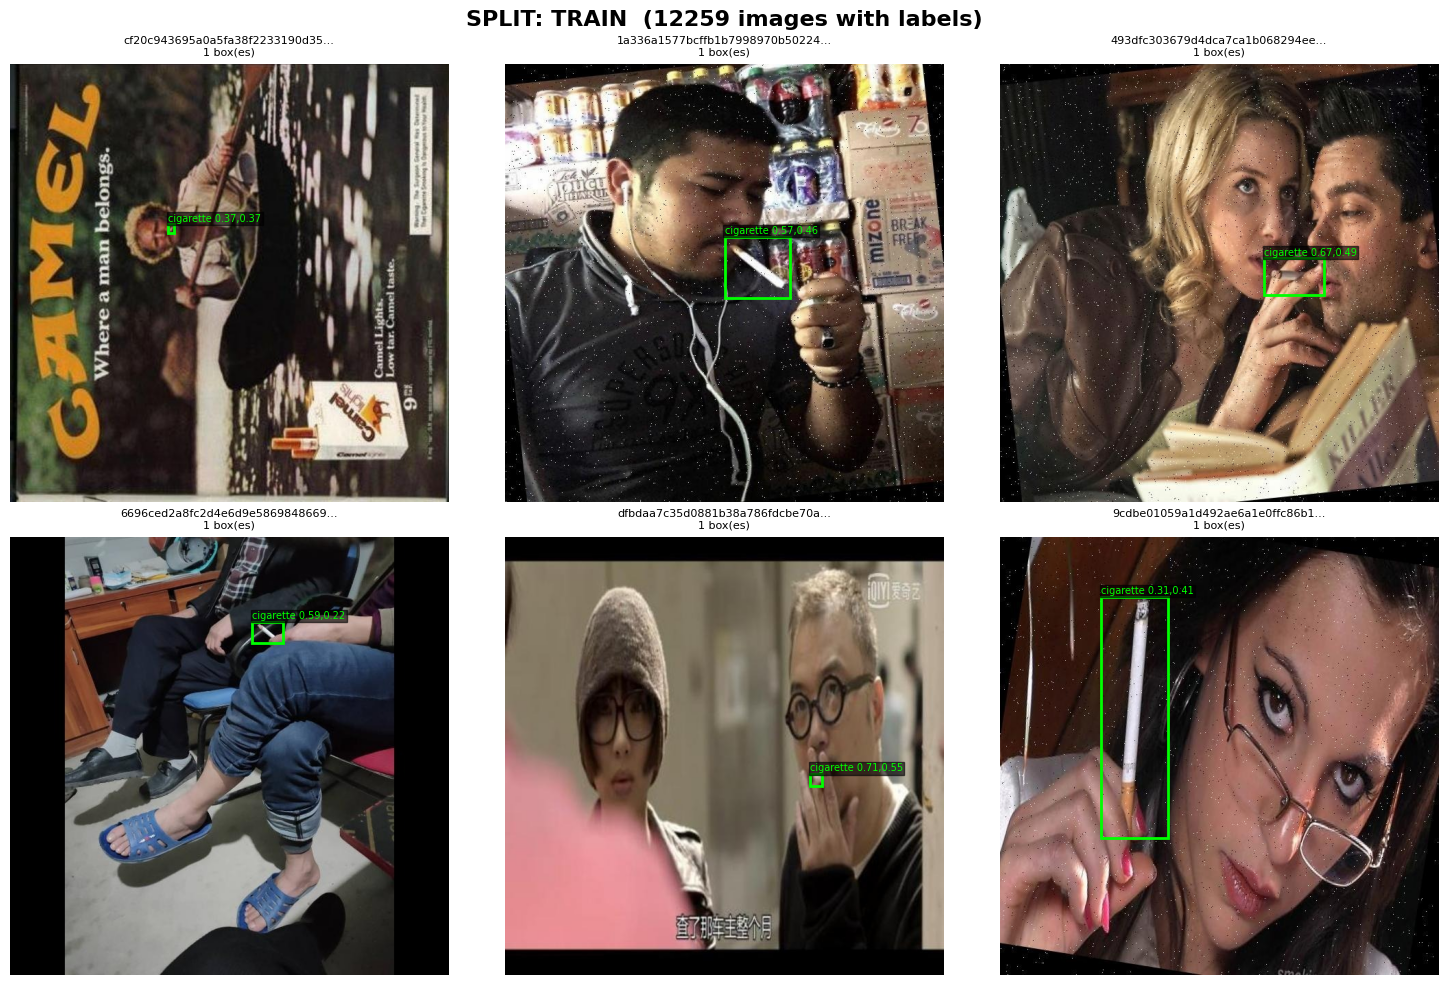

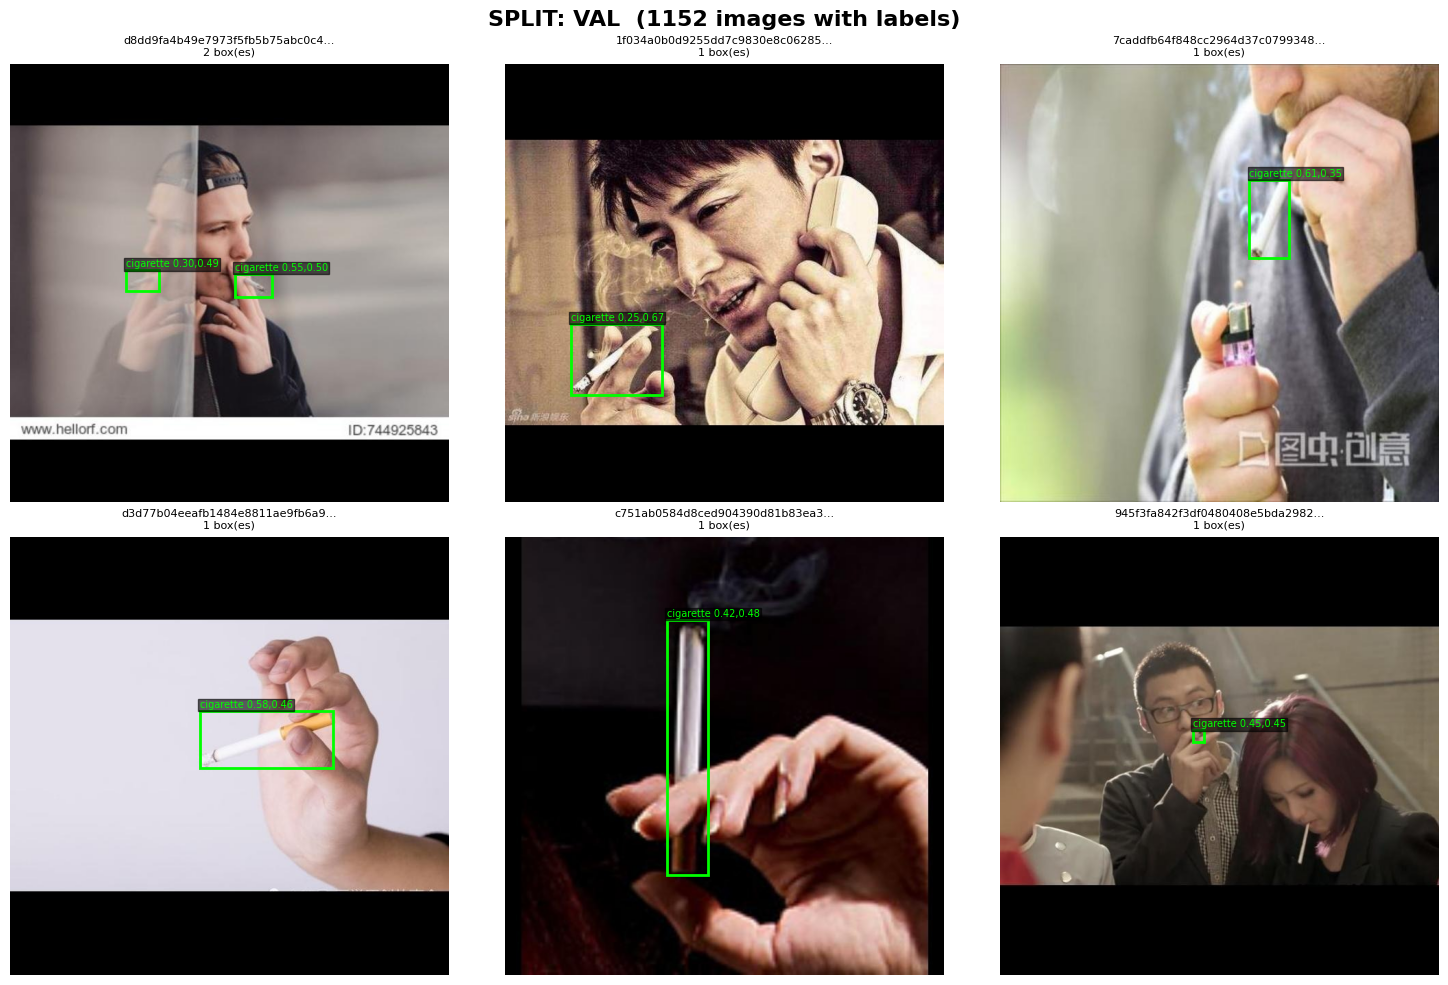

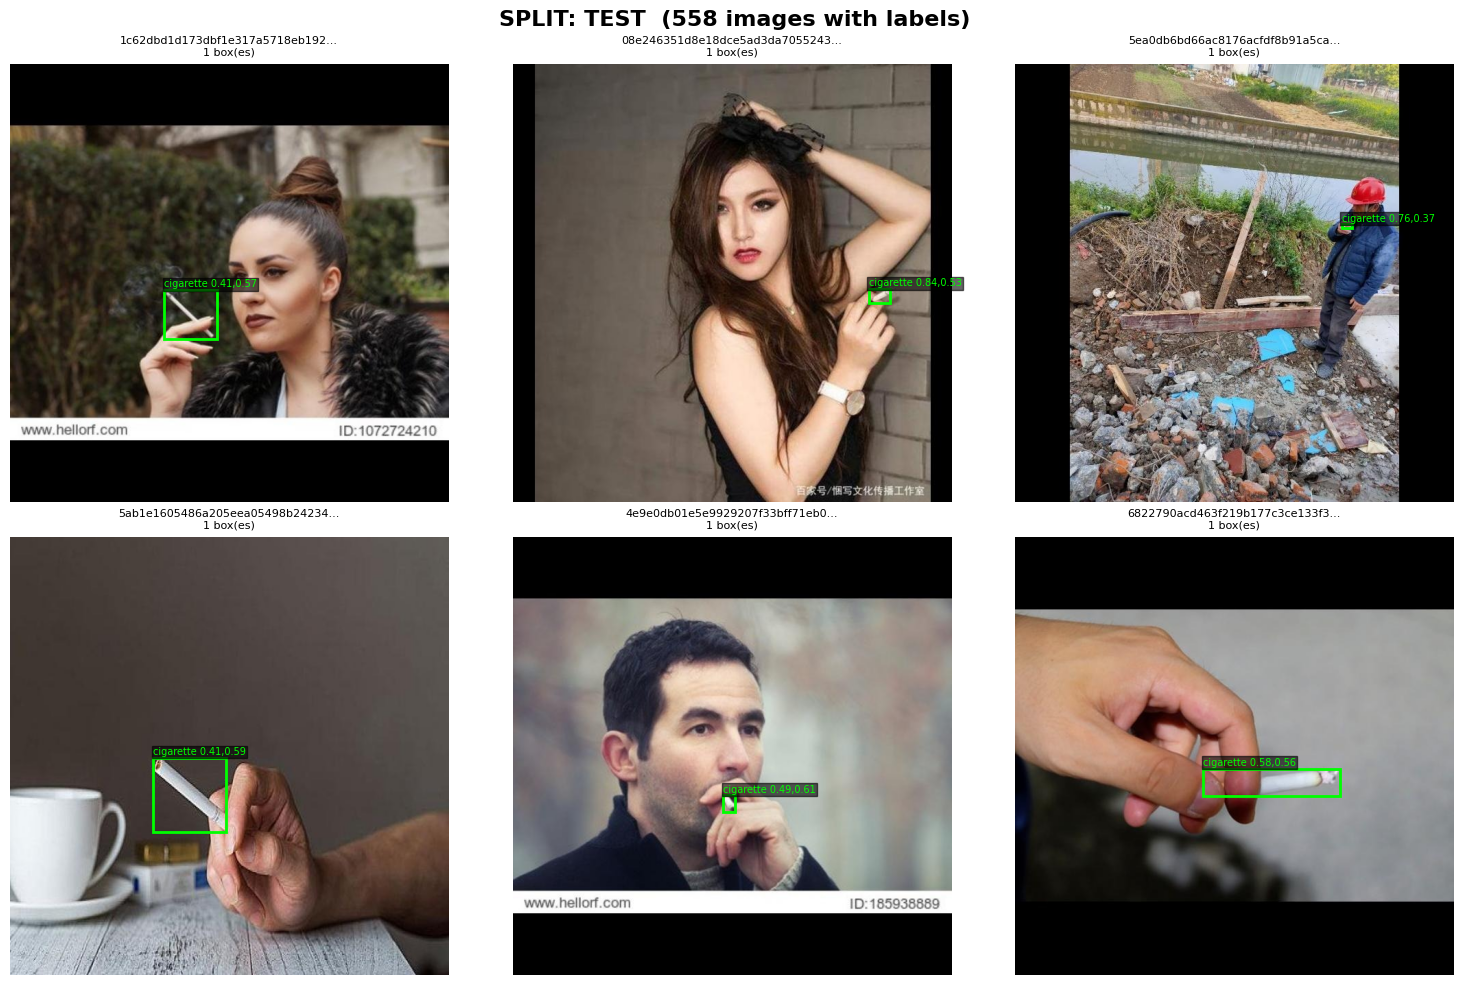

In [11]:
import os, random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

LOCAL = '/kaggle/temp/local_dataset'
random.seed(42)

def show_split(split, n=6):
    img_dir = f'{LOCAL}/images/{split}'
    lbl_dir = f'{LOCAL}/labels/{split}'

    # Pick n random images that HAVE a label file (skip backgrounds)
    imgs = [f for f in os.listdir(img_dir)
            if os.path.exists(f'{lbl_dir}/{os.path.splitext(f)[0]}.txt')]
    picks = random.sample(imgs, min(n, len(imgs)))

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle(f'SPLIT: {split.upper()}  ({len(imgs)} images with labels)',
                 fontsize=16, fontweight='bold')

    for ax, fname in zip(axes.flat, picks):
        img = Image.open(f'{img_dir}/{fname}').convert('RGB')
        W, H = img.size
        ax.imshow(img)

        stem = os.path.splitext(fname)[0]
        lbl_path = f'{lbl_dir}/{stem}.txt'

        n_boxes = 0
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue
                cls, xc, yc, bw, bh = map(float, parts)
                # YOLO → pixel xyxy
                x1 = (xc - bw/2) * W
                y1 = (yc - bh/2) * H
                w  = bw * W
                h  = bh * H
                ax.add_patch(patches.Rectangle(
                    (x1, y1), w, h,
                    linewidth=2, edgecolor='lime', facecolor='none'))
                ax.text(x1, y1 - 4, f'cigarette {xc:.2f},{yc:.2f}',
                        color='lime', fontsize=7,
                        bbox=dict(facecolor='black', alpha=0.6, pad=1))
                n_boxes += 1

        ax.set_title(f'{fname[:30]}...\n{n_boxes} box(es)', fontsize=8)
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# Run for all three splits
for split in ['train', 'val', 'test']:
    show_split(split, n=6)
    print()

## 5. Train YOLO26s
- `cache='ram'` finally works here (29 GB RAM vs Colab's 12 GB)
- `workers=4` (Kaggle gives 4 CPU cores)
- Weights → `/kaggle/working/runs/` so they persist as notebook output
- Expected: ~1.5 min/epoch → 100 epochs ≈ 2.5 hrs

In [13]:
import torch
print("Total GPUs available:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"Device {i}: {torch.cuda.get_device_name(i)}")

Total GPUs available: 2
Device 0: Tesla T4
Device 1: Tesla T4


In [16]:
# !rm -rf /kaggle/working/runs
# !rm -f /kaggle/temp/local_dataset/labels/*.cache
# !rm -f /kaggle/temp/local_dataset/labels/*/*.cache
# print('✅ Cleared runs/ and stale caches')

# import os
# for split in ['train', 'val', 'test']:
#     imgs = len(os.listdir(f'/kaggle/temp/local_dataset/images/{split}'))
#     lbls = len(os.listdir(f'/kaggle/temp/local_dataset/labels/{split}'))
#     flag = '✅' if imgs == lbls else '❌'
#     print(f'{split:<6}  images={imgs:>6}  labels={lbls:>6}  {flag}')
# print('\ndata.yaml:', os.path.exists('/kaggle/temp/local_dataset/data.yaml'))

train   images= 12259  labels= 12259  ✅
val     images=  1152  labels=  1152  ✅
test    images=   558  labels=   558  ✅

data.yaml: True


In [17]:
from ultralytics import YOLO

MODEL = 'yolo26s.pt'
PROJ  = '/kaggle/working/runs'
RUN   = 'yolo26s_run'

model = YOLO(MODEL)
model.train(
    data=yaml_path,
    epochs=60,
    imgsz=640,
    batch=32,
    device=[0, 1],
    cache='disk',
    patience=15,
    workers=4,
    project=PROJ,
    name=RUN,
    exist_ok=True,
    plots=True,
    save_period=5,
)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/temp/local_dataset/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mo

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/60      5.89G      1.904      2.001    0.01334          2        640: 100% ━━━━━━━━━━━━ 384/384 2.9it/s 2:140.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 3.1it/s 5.8s0.4s
                   all       1152       1243      0.642       0.57      0.584      0.273

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/60      5.89G      1.979      2.139    0.01476          1        640: 100% ━━━━━━━━━━━━ 384/384 3.1it/s 2:060.3sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 3.0it/s 5.9s0.3s
                   all       1152       1243      0.338      0.354      0.269      0.106

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/60      5.89G      2.052       2.37    0.01558          4        64

{'metrics/precision(B)': 0.82164,
 'metrics/recall(B)': 0.79405,
 'metrics/mAP50(B)': 0.83817,
 'metrics/mAP50-95(B)': 0.49459,
 'val/box_loss': 1.52931,
 'val/cls_loss': 0.96725,
 'val/l1_loss': 0.01081,
 'fitness': 0.49459}

In [ ]:
import os, random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from ultralytics import YOLO

# ── Config ──
BEST  = '/kaggle/working/runs/yolo26s_run/weights/best.pt'
IMGS  = '/kaggle/temp/local_dataset/images/val'
LBLS  = '/kaggle/temp/local_dataset/labels/val'
CONF  = 0.25
random.seed(42)

model = YOLO(BEST)

# ✅ Filter for real image files only (skip .npy, .cache, etc.)
VALID_EXT = ('.jpg', '.jpeg', '.png', '.webp', '.bmp')
all_imgs = [f for f in os.listdir(IMGS) if f.lower().endswith(VALID_EXT)]
print(f'Found {len(all_imgs)} real images in val (filtered out cache files)')

picks = random.sample(all_imgs, 6)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('Val inference  —  GREEN = Ground Truth   |   RED = Prediction',
             fontsize=16, fontweight='bold')

for ax, fname in zip(axes.flat, picks):
    img_path = os.path.join(IMGS, fname)
    stem     = os.path.splitext(fname)[0]
    lbl_path = os.path.join(LBLS, stem + '.txt')

    img = Image.open(img_path).convert('RGB')
    W, H = img.size
    ax.imshow(img)

    # ── Ground truth (green) ──
    gt_count = 0
    if os.path.exists(lbl_path):
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue
                cls, xc, yc, bw, bh = map(float, parts)
                x1 = (xc - bw/2) * W
                y1 = (yc - bh/2) * H
                ax.add_patch(patches.Rectangle(
                    (x1, y1), bw*W, bh*H,
                    linewidth=2, edgecolor='lime', facecolor='none'))
                ax.text(x1, y1 - 3, 'GT', color='lime', fontsize=8,
                        bbox=dict(facecolor='black', alpha=0.6, pad=1))
                gt_count += 1

    # ── Predictions (red) ──
    r = model.predict(img_path, conf=CONF, verbose=False)[0]
    pred_count = len(r.boxes)
    for box in r.boxes:
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
        conf = float(box.conf[0])
        ax.add_patch(patches.Rectangle(
            (x1, y1), x2-x1, y2-y1,
            linewidth=2, edgecolor='red', facecolor='none', linestyle='--'))
        ax.text(x1, y1 - 3, f'P {conf:.2f}', color='red', fontsize=8,
                bbox=dict(facecolor='black', alpha=0.6, pad=1))

    # Title: counts + match indicator (plain text, no emoji)
    if gt_count == pred_count:
        status = 'MATCH'
    elif gt_count == 0 and pred_count == 0:
        status = 'MATCH (bg)'
    elif pred_count > gt_count:
        status = 'OVER-PRED'
    else:
        status = 'MISSED'

    ax.set_title(f'{fname[:28]}...\nGT={gt_count}  Pred={pred_count}  [{status}]',
                 fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/kaggle/working/val_gt_vs_pred.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved: /kaggle/working/val_gt_vs_pred.png')

## 6. Check Test Images

Found 558 real test images


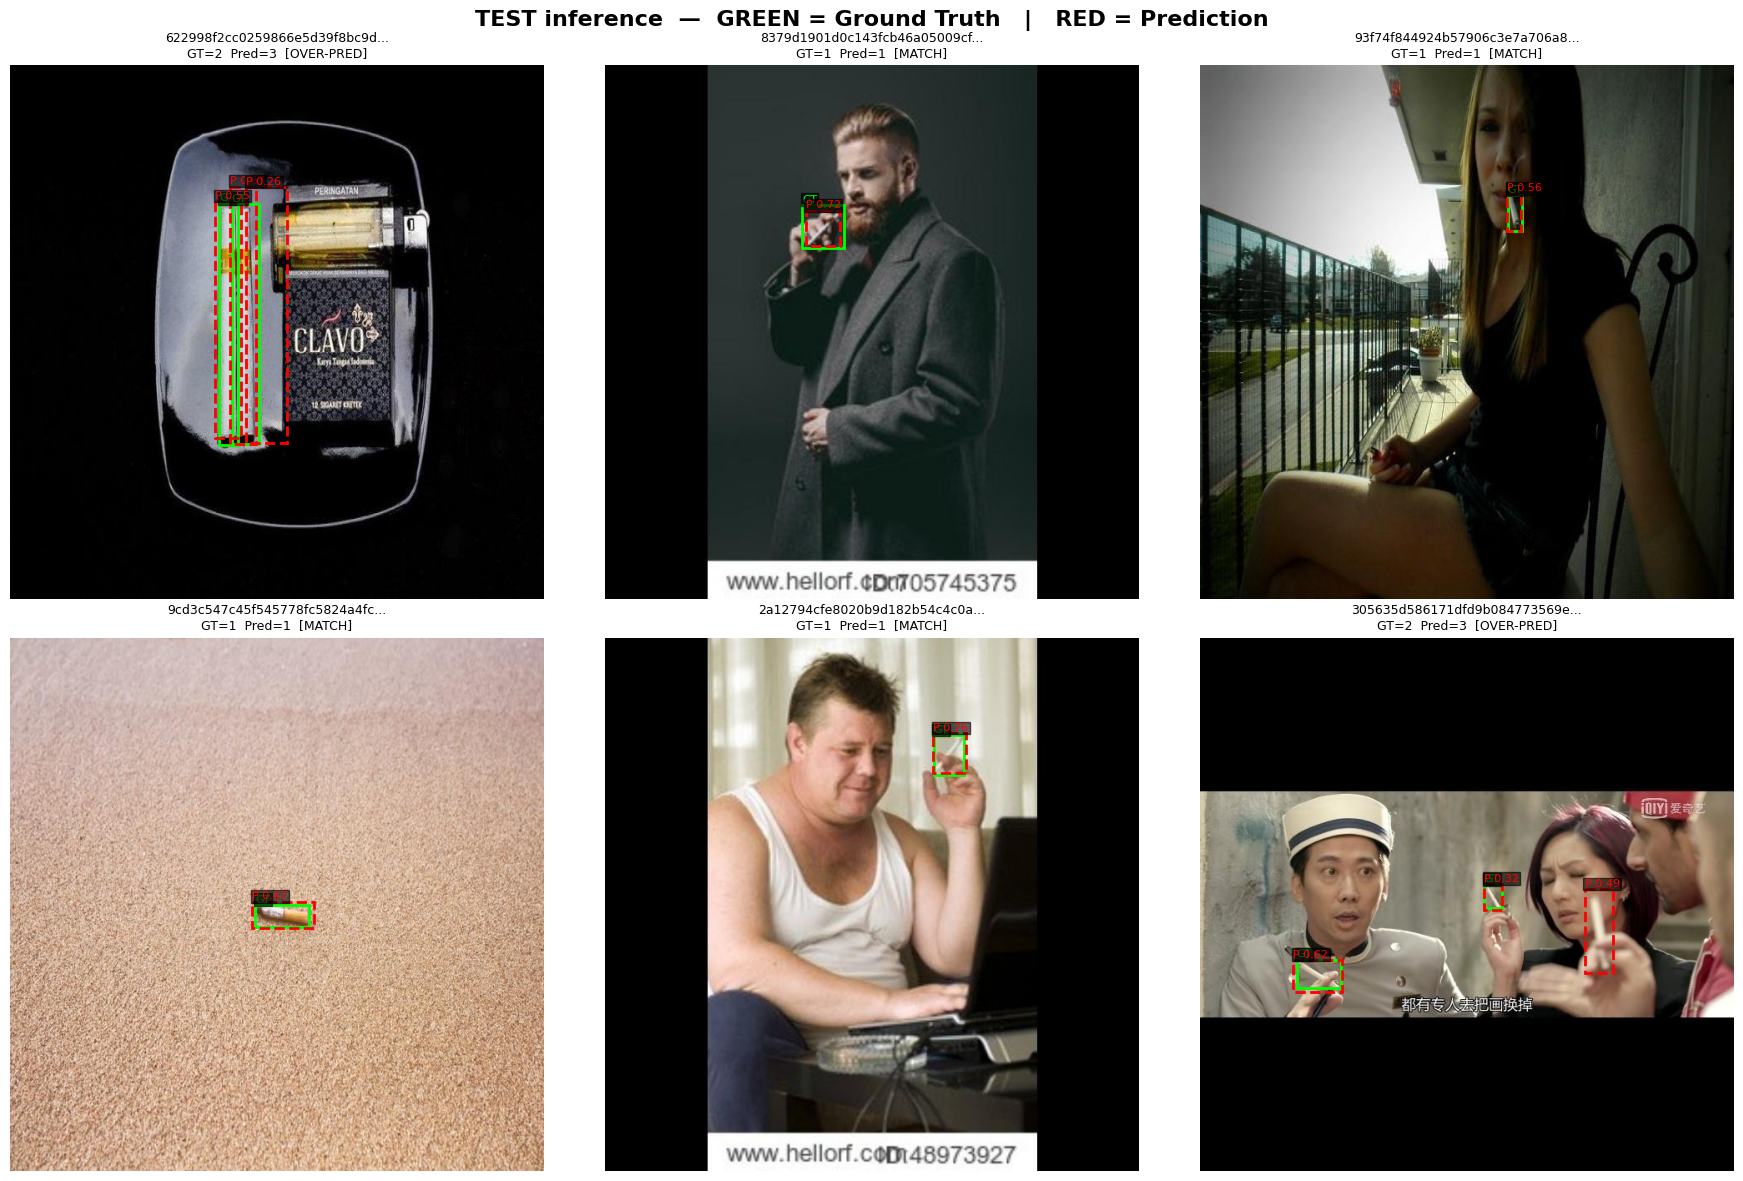

Saved: /kaggle/working/test_gt_vs_pred.png


In [22]:
import os, random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from ultralytics import YOLO

# ── Config ──
BEST  = '/kaggle/working/runs/yolo26s_run/weights/best.pt'
IMGS  = '/kaggle/temp/local_dataset/images/test'   # ← test
LBLS  = '/kaggle/temp/local_dataset/labels/test'   # ← test
CONF  = 0.25
random.seed(42)

model = YOLO(BEST)

# Filter real images only (skip .npy cache)
VALID_EXT = ('.jpg', '.jpeg', '.png', '.webp', '.bmp')
all_imgs = [f for f in os.listdir(IMGS) if f.lower().endswith(VALID_EXT)]
print(f'Found {len(all_imgs)} real test images')

picks = random.sample(all_imgs, min(6, len(all_imgs)))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('TEST inference  —  GREEN = Ground Truth   |   RED = Prediction',
             fontsize=16, fontweight='bold')

for ax, fname in zip(axes.flat, picks):
    img_path = os.path.join(IMGS, fname)
    stem     = os.path.splitext(fname)[0]
    lbl_path = os.path.join(LBLS, stem + '.txt')

    img = Image.open(img_path).convert('RGB')
    W, H = img.size
    ax.imshow(img)

    # ── Ground truth (green) ──
    gt_count = 0
    if os.path.exists(lbl_path):
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue
                cls, xc, yc, bw, bh = map(float, parts)
                x1 = (xc - bw/2) * W
                y1 = (yc - bh/2) * H
                ax.add_patch(patches.Rectangle(
                    (x1, y1), bw*W, bh*H,
                    linewidth=2, edgecolor='lime', facecolor='none'))
                ax.text(x1, y1 - 3, 'GT', color='lime', fontsize=8,
                        bbox=dict(facecolor='black', alpha=0.6, pad=1))
                gt_count += 1

    # ── Predictions (red) ──
    r = model.predict(img_path, conf=CONF, verbose=False)[0]
    pred_count = len(r.boxes)
    for box in r.boxes:
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
        c = float(box.conf[0])
        ax.add_patch(patches.Rectangle(
            (x1, y1), x2-x1, y2-y1,
            linewidth=2, edgecolor='red', facecolor='none', linestyle='--'))
        ax.text(x1, y1 - 3, f'P {c:.2f}', color='red', fontsize=8,
                bbox=dict(facecolor='black', alpha=0.6, pad=1))

    if gt_count == pred_count == 0:
        status = 'MATCH (bg)'
    elif gt_count == pred_count:
        status = 'MATCH'
    elif pred_count > gt_count:
        status = 'OVER-PRED'
    else:
        status = 'MISSED'

    ax.set_title(f'{fname[:28]}...\nGT={gt_count}  Pred={pred_count}  [{status}]',
                 fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/kaggle/working/test_gt_vs_pred.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved: /kaggle/working/test_gt_vs_pred.png')

## 7. Save weights for download
After this cell runs, open the **Output** tab (right sidebar) → download `best.pt` and `last.pt`.

In [ ]:
import shutil
shutil.copy2(f'{PROJ}/{RUN}/weights/best.pt', '/kaggle/working/yolo26s_cigarette_best.pt')
shutil.copy2(f'{PROJ}/{RUN}/weights/last.pt', '/kaggle/working/yolo26s_cigarette_last.pt')
print('✅ Copied — grab from the Output tab when training ends')

In [26]:

from ultralytics import YOLO

BEST = "/kaggle/working/runs/yolo26s_run/weights/best.pt"
model = YOLO(BEST)

metrics = model.val(
    data=yaml_path,
    split="val",
    conf=0.25,
    iou=0.50,
    plots=True,
    verbose=True,
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Confusion matrix:")
print(metrics.confusion_matrix.matrix)


Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1061.5±330.9 MB/s, size: 67.5 KB)
val: Scanning /kaggle/temp/local_dataset/labels/val.cache... 1152 images, 88 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1152/1152 146.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 72/72 4.5it/s 16.0s0.2s
                   all       1152       1243      0.826      0.822      0.777      0.455
Speed: 1.1ms preprocess, 9.4ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-2
Precision: 0.826192400970089
Recall: 0.8222043443282381
mAP50: 0.7769033700361794
mAP50-95: 0.4549898043866727
Confusion matrix:
[[       1048         189]
 [        195           0]]


In [28]:

from ultralytics import YOLO

BEST = "/kaggle/working/runs/yolo26s_run/weights/best.pt"
DATA = yaml_path  # Reuse your actual training YAML path

model = YOLO(BEST)

for conf in [0.001, 0.25]:
    metrics = model.val(
        data=DATA,
        split="val",
        imgsz=640,
        conf=conf,
        plots=True,
        project="/kaggle/working/runs/diagnostic",
        name=f"conf_{conf}",
        exist_ok=True,
    )

    print(f"\nConfidence threshold: {conf}")
    print("Precision:", metrics.box.mp)
    print("Recall:", metrics.box.mr)
    print("mAP50:", metrics.box.map50)
    print("Confusion matrix:")
    print(metrics.confusion_matrix.matrix)


Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 817.8±150.9 MB/s, size: 42.8 KB)
val: Scanning /kaggle/temp/local_dataset/labels/val.cache... 1152 images, 88 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1152/1152 185.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 72/72 4.4it/s 16.2s0.2s
                   all       1152       1243       0.82      0.795      0.838      0.495
Speed: 1.1ms preprocess, 9.3ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /kaggle/working/runs/diagnostic/conf_0.001

Confidence threshold: 0.001
Precision: 0.8196508426561873
Recall: 0.7948511665325825
mAP50: 0.8377211068599031
Confusion matrix:
[[       1183        9379]
 [         60           0]]
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 

# Trying Videos

In [30]:
import os, zipfile

FILE_ID = '1uQQcXls8mdWmQ00HwCTs_j69JFkjPz0F'   # from your share link
ZIP     = '/kaggle/working/Test_Videos.zip'
DEST    = '/kaggle/working/test_videos'

# ── Download ──
if not os.path.exists(ZIP):
    print('📥 Downloading from Drive...')
    !gdown --id {FILE_ID} -O {ZIP}
else:
    print('✅ already downloaded')

# ── Verify ──
size_mb = os.path.getsize(ZIP) / 1e6
print(f'📦 ZIP size: {size_mb:.1f} MB')

# ── Extract ──
os.makedirs(DEST, exist_ok=True)
with zipfile.ZipFile(ZIP, 'r') as z:
    z.extractall(DEST)

print(f'✅ Extracted to: {DEST}')
print('\nContents:')
!find {DEST} -type f | head -30

📥 Downloading from Drive...
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1uQQcXls8mdWmQ00HwCTs_j69JFkjPz0F
To: /kaggle/working/Test_Videos.zip
100%|██████████████████████████████████████| 16.3M/16.3M [00:00<00:00, 56.6MB/s]
📦 ZIP size: 16.3 MB
✅ Extracted to: /kaggle/working/test_videos

Contents:
/kaggle/working/test_videos/Test_Videos/Workers_Smoking.webm
/kaggle/working/test_videos/Test_Videos/Close_up.mp4
/kaggle/working/test_videos/Test_Videos/Nurse_Smoking.webm
/kaggle/working/test_videos/Test_Videos/Random_Smoking.mp4
/kaggle/working/test_videos/Test_Videos/Worker_Smoking_in_OIL_RIG.mp4


In [43]:
import gc
from pathlib import Path
from ultralytics import YOLO

BEST    = '/kaggle/working/runs/yolo26s_run/weights/best.pt'
VID_DIR = '/kaggle/working/test_videos/Test_Videos'
OUT_DIR = '/kaggle/working/video_demo'
CONF    = 0.3

VIDEO_EXTS = {'.mp4', '.avi', '.mov', '.mkv', '.webm'}

model = YOLO(BEST)

videos = sorted(
    p for p in Path(VID_DIR).iterdir()
    if p.is_file() and p.suffix.lower() in VIDEO_EXTS
)

print(f'🎥 Found {len(videos)} videos')

for video in videos:
    print(f'\n━━━ {video.stem} ━━━')

    results = model.predict(
        source=str(video),
        stream=True,       # Prevents accumulating all frame results
        conf=CONF,
        imgsz=1280,
        save=True,
        project=OUT_DIR,
        name=video.stem,
        exist_ok=True,
        verbose=False,
    )

    frame_count = 0
    detections = 0

    for result in results:
        frame_count += 1
        detections += len(result.boxes)

    print(f'✅ Processed {frame_count} frames')
    print(f'📦 Total detections across frames: {detections}')
    print(f'📁 Saved to: {OUT_DIR}/{video.stem}')

    del results
    gc.collect()

print('\n🎉 All videos processed!')
print(f'📁 Output directory: {OUT_DIR}')


🎥 Found 5 videos

━━━ Close_up ━━━
Results saved to /kaggle/working/video_demo/Close_up
✅ Processed 257 frames
📦 Total detections across frames: 105
📁 Saved to: /kaggle/working/video_demo/Close_up

━━━ Nurse_Smoking ━━━
Results saved to /kaggle/working/video_demo/Nurse_Smoking
✅ Processed 335 frames
📦 Total detections across frames: 443
📁 Saved to: /kaggle/working/video_demo/Nurse_Smoking

━━━ Random_Smoking ━━━
Results saved to /kaggle/working/video_demo/Random_Smoking
✅ Processed 744 frames
📦 Total detections across frames: 1119
📁 Saved to: /kaggle/working/video_demo/Random_Smoking

━━━ Worker_Smoking_in_OIL_RIG ━━━
Results saved to /kaggle/working/video_demo/Worker_Smoking_in_OIL_RIG
✅ Processed 1190 frames
📦 Total detections across frames: 616
📁 Saved to: /kaggle/working/video_demo/Worker_Smoking_in_OIL_RIG

━━━ Workers_Smoking ━━━
Results saved to /kaggle/working/video_demo/Workers_Smoking
✅ Processed 658 frames
📦 Total detections across frames: 255
📁 Saved to: /kaggle/working/vid

In [44]:

from pathlib import Path
from IPython.display import FileLink, display
import zipfile

OUT_DIR = Path("/kaggle/working/video_demo")
ZIP_PATH = Path("/kaggle/working/video_demo.zip")

assert OUT_DIR.exists(), f"Output folder not found: {OUT_DIR}"

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zf:
    for file in OUT_DIR.rglob("*"):
        if file.is_file():
            zf.write(file, file.relative_to(OUT_DIR))

print(f"ZIP created: {ZIP_PATH}")
print(f"Size: {ZIP_PATH.stat().st_size / (1024**2):.1f} MB")


ZIP created: /kaggle/working/video_demo.zip
Size: 179.8 MB


In [ ]:
# !rm -rf /kaggle/working/video_demo
# !rm -f /kaggle/working/video_demo.zip